# DNN Assignment 1 - Cats vs Dogs

**Student name** Abhishek Jha  
**Student ID** 2026CS05046

The task is to tell whether a photo shows a cat or a dog. I used a small Dense neural network and trained it with SGD.

The model got 66.85% accuracy on the test photos.

## 1. Import the required libraries

Run the notebook from top to bottom. In a local Python environment, install the packages with `pip install tensorflow scikit-learn pillow matplotlib`. The dataset download is about 787 MiB.

In [1]:
from hashlib import sha256
from time import perf_counter
import warnings
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, train_test_split
from tensorflow import keras

seed = 12
image_size = (32, 32)
class_names = ["Cat", "Dog"]

## 2. Data acquisition

### 2.1 Load the images

I used Microsoft's PetImages ZIP, the source archive for the [Cats vs Dogs dataset in the TensorFlow catalog](https://www.tensorflow.org/datasets/catalog/cats_vs_dogs). The folder name gives the label for each JPEG. Each image is read as RGB and resized to 32 × 32 so all images have the same shape. I read the original ZIP with Pillow, so the readable image count comes from this notebook's own checks.

In [2]:
zip_name = "kagglecatsanddogs_5340.zip"
data_url = (
    "https://download.microsoft.com/download/3/E/1/"
    "3E1C3F21-ECDB-4869-8368-6DEBA77B919F/" + zip_name
)
archive_hash = (
    "b7974bd00a84a99921f36ee4403f089853777b5ae8d151c76a86e64900334af9"
)
zip_path = keras.utils.get_file(
    fname=zip_name, origin=data_url, file_hash=archive_hash,
)

In [3]:
images = []
labels = []
skipped = 0
# Read the photos straight from the ZIP to save disk space.
with ZipFile(zip_path) as archive:
    for label, class_name in enumerate(class_names):
        folder = f"PetImages/{class_name}/"
        for filename in sorted(archive.namelist()):
            if not filename.startswith(folder) or not filename.endswith(".jpg"):
                continue
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter("error", UserWarning)
                    with archive.open(filename) as photo, Image.open(photo) as image:
                        image = image.convert("RGB").resize(image_size)
                        images.append(np.asarray(image))
                labels.append(label)
            except (OSError, UserWarning, Image.DecompressionBombError):
                skipped += 1

images = np.stack(images)
labels = np.array(labels)
print(f"JPEG files in the archive: {len(images) + skipped:,}")
print(f"Images read: {len(images):,}")
print(f"Unreadable images skipped: {skipped}")

JPEG files in the archive: 25,000
Images read: 24,997
Unreadable images skipped: 3


### 2.2 Observations

Each observation is a photo with three numeric pixel channels (red, green and blue) and one category (cat or dog). The archive has 25,000 JPEGs. The plot counts the readable files in each category before duplicate removal.

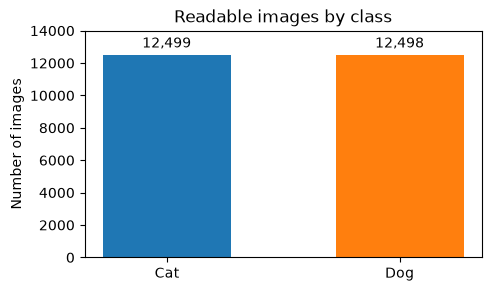

In [4]:
counts = np.bincount(labels)
fig, ax = plt.subplots(figsize=(4.8, 2.8), layout="constrained")
bars = ax.bar(class_names, counts, color=["tab:blue", "tab:orange"], width=0.55)
ax.bar_label(bars, labels=[f"{count:,}" for count in counts], padding=3)
ax.set(ylim=(0, 14000), ylabel="Number of images", title="Readable images by class")
plt.show()

## 3. Data preparation

### 3.1 Remove duplicates and scale the pixels

I compared the resized RGB images before splitting. I kept one copy when the pixels and labels matched. If the same pixels had both labels, I dropped all copies because the label would be ambiguous. I then divided the pixels by 255 to put them on a 0 to 1 scale.

In [5]:
seen = {}
conflicting_images = set()
# Use the resized pixels as the key so copies stay in the same group.
for index, (image, label) in enumerate(zip(images, labels)):
    image_key = sha256(image.tobytes()).digest()
    if image_key not in seen:
        seen[image_key] = index
    elif labels[seen[image_key]] != label:
        conflicting_images.add(image_key)

keep = [index for key, index in seen.items() if key not in conflicting_images]
duplicates_removed = len(images) - len(seen)
print(f"Repeated image copies removed: {duplicates_removed}")
print(f"Unique images dropped for conflicting labels: {len(conflicting_images)}")

X = images[keep].reshape(len(keep), -1).astype("float32") / 255
labels = labels[keep]

Repeated image copies removed: 30
Unique images dropped for conflicting labels: 2


### 3.2 Features and target

`X` has 3,072 pixel values per image (32 × 32 × 3). For `y`, I used `[1, 0]` for a cat and `[0, 1]` for a dog. These two-element labels match the two softmax outputs and the categorical cross-entropy loss.

In [6]:
y = keras.utils.to_categorical(labels, num_classes=2)
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (24965, 3072)
Shape of y: (24965, 2)


### 3.3 Split into training and test data

I set aside 20% for testing. Stratification keeps about the same proportion of cats and dogs in both sets. The five training and validation folds come from the other 80%.

In [7]:
train_idx, test_idx = train_test_split(
    np.arange(len(y)), test_size=0.2, stratify=labels, random_state=seed
)
X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
train_labels, test_labels = labels[train_idx], labels[test_idx]

### 3.4 Preprocessing report

The unreadable files were skipped because they could not supply complete pixels. Resizing fixed the difference in image dimensions, and converting to RGB gave every image three channels. The remaining inputs were checked for missing values after scaling. The labels came from the two folder names, so one-hot encoding was the only categorical conversion.

In [8]:
assert np.isfinite(X).all()
assert not np.intersect1d(train_idx, test_idx).size
print(f"Training pool: {len(X_train):,} images")
print(f"Test set: {len(X_test):,} images")
print(f"Pixel values after scaling: {X.min():.1f} to {X.max():.1f}")

Training pool: 19,972 images
Test set: 4,993 images
Pixel values after scaling: 0.0 to 1.0


## 4. Deep neural network architecture

### 4.1 Build the model

The model takes a row of pixels and passes it through two hidden Dense layers with ReLU. The output has two units with softmax, so it gives a score for each class and the scores add to 1.

In [9]:
def build_model():
    return keras.Sequential([
        keras.Input(shape=(3072,)),
        keras.layers.Dense(128, activation="relu", name="hidden_1"),
        keras.layers.Dense(64, activation="relu", name="hidden_2"),
        keras.layers.Dense(2, activation="softmax", name="output"),
    ])

model = build_model()
for layer in model.layers:
    print(f"{layer.name}: {layer.units} units, {layer.count_params():,} parameters")
print(f"Total trainable parameters: {model.count_params():,}")

hidden_1: 128 units, 393,344 parameters
hidden_2: 64 units, 8,256 parameters
output: 2 units, 130 parameters
Total trainable parameters: 401,730


### 4.2 DNN report

There are three Dense layers. The first hidden layer has 128 units and the second has 64. I made the second layer smaller to keep the model size down. ReLU lets the hidden layers learn nonlinear patterns. The output has 2 units because there are 2 classes. Each Dense unit has one weight per input and one bias, so the three layers have 401,730 trainable parameters in total.

## 5. Training the model

### 5.1 Configure training

I used SGD with momentum set to 0.9 to smooth the updates between batches. I added a small weight decay to discourage large weights. The loss is categorical cross-entropy, and accuracy is the fraction of correctly classified images.

In [10]:
epochs = 20
batch_size = 256
learning_rates = [0.01, 0.03]


def compile_model(model, learning_rate):
    model.compile(
        optimizer=keras.optimizers.SGD(
            learning_rate=learning_rate, momentum=0.9, weight_decay=0.0005
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )

### 5.2 Train with cross-validation

For each learning rate, I trained a fresh model for 20 epochs on each of five folds. Each time, four folds were used for training and one for validation. I picked the rate with the higher mean validation accuracy at epoch 20, then trained a fresh model for 20 epochs on the whole training pool.

In [11]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
histories = {}
scores = {}
training_start = perf_counter()

for rate in learning_rates:
    histories[rate] = []
    for fold, (fit_idx, val_idx) in enumerate(folds.split(X_train, train_labels), 1):
        keras.backend.clear_session()
        # Start the same fold from the same seed for both learning rates.
        keras.utils.set_random_seed(seed + fold)
        model = build_model()
        compile_model(model, rate)
        start = perf_counter()
        history = model.fit(
            X_train[fit_idx], y_train[fit_idx],
            validation_data=(X_train[val_idx], y_train[val_idx]),
            epochs=epochs, batch_size=batch_size, verbose=0,
        ).history
        histories[rate].append(history)
        print(f"LR {rate:.2f}, fold {fold}: {history['val_accuracy'][-1]:.2%} "
              f"validation accuracy, {perf_counter() - start:.1f} s")

    scores[rate] = np.mean([h["val_accuracy"][-1] for h in histories[rate]])
    print(f"Mean validation accuracy for LR {rate:.2f}: {scores[rate]:.2%}")

best_rate = max(scores, key=scores.get)
print(f"Cross-validation time: {perf_counter() - training_start:.1f} s")
print(f"Selected learning rate: {best_rate:.2f}")

LR 0.01, fold 1: 65.16% validation accuracy, 3.0 s


LR 0.01, fold 2: 64.16% validation accuracy, 3.1 s


LR 0.01, fold 3: 62.42% validation accuracy, 2.9 s


LR 0.01, fold 4: 65.92% validation accuracy, 2.8 s


LR 0.01, fold 5: 64.55% validation accuracy, 3.2 s
Mean validation accuracy for LR 0.01: 64.44%


LR 0.03, fold 1: 62.15% validation accuracy, 2.9 s


LR 0.03, fold 2: 64.21% validation accuracy, 3.0 s


LR 0.03, fold 3: 63.75% validation accuracy, 3.0 s


LR 0.03, fold 4: 63.82% validation accuracy, 3.0 s


LR 0.03, fold 5: 64.85% validation accuracy, 2.9 s
Mean validation accuracy for LR 0.03: 63.75%
Cross-validation time: 30.3 s
Selected learning rate: 0.01


In [12]:
keras.backend.clear_session()
keras.utils.set_random_seed(seed)
model = build_model()
compile_model(model, best_rate)
start = perf_counter()
model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, verbose=0)
print(f"Final training time for {epochs} epochs: {perf_counter() - start:.1f} s")
print(f"Total training time: {perf_counter() - training_start:.1f} s")

Final training time for 20 epochs: 3.0 s
Total training time: 33.3 s


The learning rate controls how big each update is. I tried two values to see whether larger steps worked better with this setup. The batch size, number of epochs, momentum and weight decay were held fixed for both runs.

## 6. Test the model

I used the held-out photos to measure how well the final model did on images it had not seen during training. The predicted class is the one with the higher softmax score.

In [13]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
predictions = model.predict(X_test, verbose=0).argmax(axis=1)
baseline = np.bincount(test_labels).max() / len(test_labels)
assert np.isclose(test_accuracy, (predictions == test_labels).mean())
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")
print(f"Accuracy if every photo is given the most common label: {baseline:.2%}")

Test loss: 0.6129
Test accuracy: 66.85%
Accuracy if every photo is given the most common label: 50.01%


## 7. Results

### Training and validation history

The lines show the mean across the five folds for the chosen learning rate.

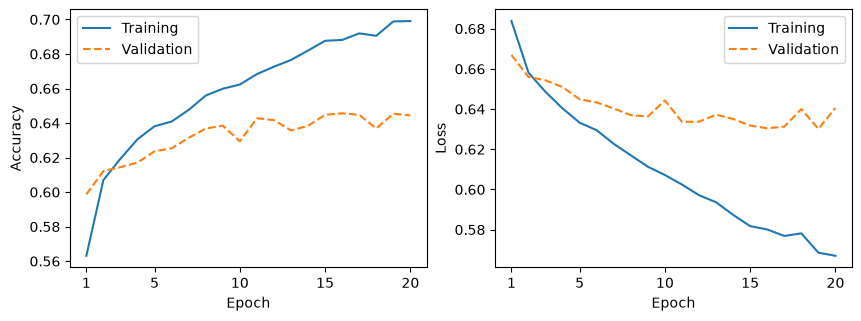

In [14]:
epoch_numbers = np.arange(1, epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.1), layout="constrained")
for ax, metric, title in zip(axes, ["accuracy", "loss"], ["Accuracy", "Loss"]):
    for prefix, label, style in [("", "Training", "-"), ("val_", "Validation", "--")]:
        values = [history[prefix + metric] for history in histories[best_rate]]
        ax.plot(epoch_numbers, np.mean(values, axis=0), style, label=label)
    ax.set(xlabel="Epoch", ylabel=title, xticks=[1, 5, 10, 15, 20])
    ax.legend()
plt.show()

### Confusion matrix

The main diagonal shows the correct predictions. The other two boxes show how often the model mixed up the classes.

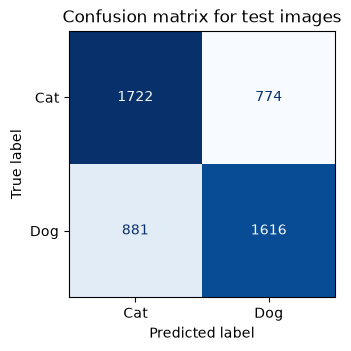

In [15]:
fig, ax = plt.subplots(figsize=(4.1, 3.4), layout="constrained")
ConfusionMatrixDisplay.from_predictions(
    test_labels, predictions, display_labels=class_names,
    cmap="Blues", values_format="d", colorbar=False, ax=ax,
)
ax.set_title("Confusion matrix for test images")
plt.show()

### Precision, recall and F1-score

Precision tells me how often a predicted label was right. Recall tells me how many photos of that class the model found. F1 combines the two.

In [16]:
print(classification_report(
    test_labels, predictions, target_names=class_names, digits=3
))

              precision    recall  f1-score   support

         Cat      0.662     0.690     0.675      2496
         Dog      0.676     0.647     0.661      2497

    accuracy                          0.669      4993
   macro avg      0.669     0.669     0.668      4993
weighted avg      0.669     0.669     0.668      4993



## 8. Conclusion

The model got 3,338 out of 4,993 test photos right (66.85%). Always choosing the most common label would give 50.01%. The model found 69.0% of the cats and 64.7% of the dogs.

After about epoch 10, training accuracy kept rising while validation accuracy stayed around 64%. That suggests some overfitting. Resizing the photos to 32 × 32 also loses small details that could help tell the two classes apart.